# Bons e Maus Pagadores

Análise Exploratória de Dados · Give Me Some Credit

Por [Leonardo Dias Trindade da Silva](https://github.com/LeoDiasTrindade)

![Python](https://img.shields.io/badge/Python-3.11+-333333?style=for-the-badge&logo=python&logoColor=white)
[![Dataset](https://img.shields.io/badge/Dataset-Kaggle-333333?style=for-the-badge&logo=kaggle&logoColor=white)](https://www.kaggle.com/c/GiveMeSomeCredit)
[![GitHub](https://img.shields.io/badge/GitHub-Reposit%C3%B3rio-333333?style=for-the-badge&logo=github&logoColor=white)](https://github.com/LeoDiasTrindade/bons-maus-pagadores/)<br>
[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/LeoDiasTrindade/bons-maus-pagadores/blob/main/notebooks/01_eda.ipynb)<br><br><br>

---

In [4]:
# @title Configurando o ambiente { display-mode: "form" }

from IPython.display import clear_output
from google.colab import userdata
import os, sys

token = userdata.get('GITHUB_TOKEN')

if 'google.colab' in sys.modules:
    if os.path.basename(os.getcwd()) != 'notebook':
        !git clone https://{token}@github.com/LeoDiasTrindade/bons-maus-pagadores.git
        %cd bons-maus-pagadores/notebook
    !pip install -e .. -q

clear_output()

In [ ]:
%matplotlib inline
import matplotlib.pyplot as plt
import seaborn as sns; sns.set()
import numpy as np, pandas as pd

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.feature_selection import mutual_info_classif

from optbinning import OptimalBinning

from pathlib import Path

from IPython.display import display, clear_output

In [ ]:
PATHFILE = Path.cwd().parent / 'data' / 'raw' / 'cs-training.csv'
TARGET_NAME = 'SeriousDlqin2yrs'

tratamentos = {}

#### Levantamento dados de treino da base
Aqui vamos usar base já splitada cs-training, disponível em data/raw a partir da extração feita pelo makefile dos dados da competição _Can you give me some credit_.<br>
Extração dos dados de treino 150k instâncias, 10 features numéricas, 1 alvo binário.<br>
Dados faltantes nas features MonthlyIncome e NumberOfDependents

In [3]:
train_df_raw = pd.read_csv(PATHFILE, index_col=0)

display(train_df_raw.head(1))
train_df_raw.info()

,SeriousDlqin2yrs,RevolvingUtilizationOfUnsecuredLines,age,NumberOfTime30-59DaysPastDueNotWorse,DebtRatio,MonthlyIncome,NumberOfOpenCreditLinesAndLoans,NumberOfTimes90DaysLate,NumberRealEstateLoansOrLines,NumberOfTime60-89DaysPastDueNotWorse,NumberOfDependents
1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0


<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 1 to 150000
Data columns (total 11 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   SeriousDlqin2yrs                      150000 non-null  int64  
 1   RevolvingUtilizationOfUnsecuredLines  150000 non-null  float64
 2   age                                   150000 non-null  int64  
 3   NumberOfTime30-59DaysPastDueNotWorse  150000 non-null  int64  
 4   DebtRatio                             150000 non-null  float64
 5   MonthlyIncome                         120269 non-null  float64
 6   NumberOfOpenCreditLinesAndLoans       150000 non-null  int64  
 7   NumberOfTimes90DaysLate               150000 non-null  int64  
 8   NumberRealEstateLoansOrLines          150000 non-null  int64  
 9   NumberOfTime60-89DaysPastDueNotWorse  150000 non-null  int64  
 10  NumberOfDependents                    146076 non-null  float64
dtypes: float64(

In [4]:
train_df = train_df_raw.copy()

## Análise Consistência dos dados

Primeira análise sobre sujeiras, dados faltantes e possíveis correlações entre as features

---

### Análise da coluna RevolvingUtilizationOfUnsecuredLines 

Razao uso rotativo pela soma do limite de crédito

In [5]:
uso_rotativo = train_df_raw.RevolvingUtilizationOfUnsecuredLines

In [42]:
uso_rotativo.describe()

count    150000.000000
mean          6.048438
std         249.755371
min           0.000000
25%           0.029867
50%           0.154181
75%           0.559046
max       50708.000000
Name: RevolvingUtilizationOfUnsecuredLines, dtype: float64

Desbalanceada, maior parte dos clientes nunca usou rotativo.<br>
Maiores valores não são compatíveis, provável erro na base.

In [6]:
uso_rotativo.value_counts().sort_index()

RevolvingUtilizationOfUnsecuredLines
0.000000        10878
0.000008            1
0.000010            1
0.000013            1
0.000014            1
                ...  
20514.000000        1
22000.000000        1
22198.000000        1
29110.000000        1
50708.000000        1
Name: count, Length: 125728, dtype: int64

99% dos valores estão abaixo de 1,1. Valores extremos de 1000 até
50708 aparecem em uma minoria dos casos.

In [7]:
uso_rotativo.quantile([0.9, 0.95, 0.99, 0.999, 0.9999, 1.0])

0.9000        0.981278
0.9500        1.000000
0.9900        1.092956
0.9990     1571.006000
0.9999    10151.005800
1.0000    50708.000000
Name: RevolvingUtilizationOfUnsecuredLines, dtype: float64

A partir de 4, a redução no número de linhas é gradual.

In [8]:
for limite in [1,2,3,4,5,10,20,50,100]:
    n = (uso_rotativo > limite).sum()
    print(f'> {limite}: {n} linhas')

> 1: 3321 linhas
> 2: 371 linhas
> 3: 292 linhas
> 4: 264 linhas
> 5: 254 linhas
> 10: 241 linhas
> 20: 234 linhas
> 50: 230 linhas
> 100: 223 linhas


#### Tratamento 
Aqui tomo a decisão de considerar uso maior que 400% como erro, anulando as linhas correspondentes.

In [9]:
train_df.loc[uso_rotativo > 4, 'RevolvingUtilizationOfUnsecuredLines'] = np.nan

### Análise da coluna age

In [ ]:
idades = train_df_raw.age

In [ ]:
idades.describe()

count    150000.000000
mean         52.295207
std          14.771866
min           0.000000
25%          41.000000
50%          52.000000
75%          63.000000
max         109.000000
Name: age, dtype: float64

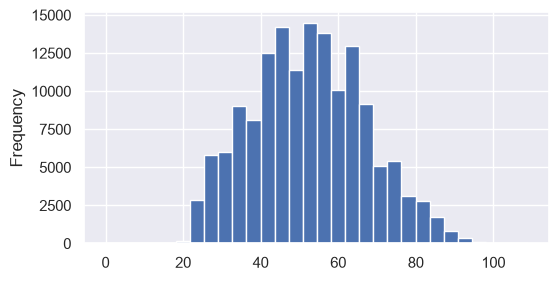

In [11]:
idades.plot(kind='hist', bins=30, figsize=(6, 3));

Não deveria aparecer menores de idade na base (muito menos um recém nacido).

In [12]:
idades[idades < 18]

65696    0
Name: age, dtype: int64

#### WOE

In [ ]:
idades.quantile([0.05, 0.25, .5, 0.75, 0.9, 0.99]) # se eu fizer por quantiles, é possível que eu tenha grupos de idade super-representados, perdendo informação sobre como jovens podem ser maus pagadores por exemplo

0.05    29.0
0.25    41.0
0.50    52.0
0.75    63.0
0.90    72.0
0.99    87.0
Name: age, dtype: float64

In [ ]:
testes['categorias_age'] = pd.cut(testes.age, [0, 30, 45, 60, np.inf], labels=[1, 2, 3, 4]).to_numpy()
soma = testes[['categorias_age', 'SeriousDlqin2yrs']].groupby('categorias_age').sum().rename(columns={'SeriousDlqin2yrs': 'soma'})
contagem = testes[['categorias_age', 'SeriousDlqin2yrs']].groupby('categorias_age').count().rename(columns={'SeriousDlqin2yrs': 'contagem'})
n, n_maus_pagadores = len(testes), testes.SeriousDlqin2yrs.sum()
n_bons_pagadores = n - n_maus_pagadores
WOE = soma.join(contagem).assign(WOE = lambda df: np.log(((df.contagem - df.soma) / (n - n_maus_pagadores)) / (df.soma/(n_maus_pagadores))))
WOE.assign(relacao_bons_maus_pagadores = lambda df: ((df.contagem-df.soma)/n_bons_pagadores - df.soma/n_maus_pagadores)*df.WOE).relacao_bons_maus_pagadores.sum()

testes = (
    testes
    .join(WOE.WOE, on='categorias_age')
    .drop('categorias_age', axis=1)
    .rename(columns={'WOE':'WOE-age'})
)

#### Tratamento

In [13]:
# TODO: implementar tratamento da idade na pipeline
train_df.loc[idades == 0, 'age'] = np.nan

### Análise sobre as colunas frequência de atrasos no pagamento

In [14]:
atrasos = train_df_raw[['NumberOfTime30-59DaysPastDueNotWorse',
                        'NumberOfTime60-89DaysPastDueNotWorse',
                        'NumberOfTimes90DaysLate']]

In [44]:
atrasos.describe()

,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTime60-89DaysPastDueNotWorse,NumberOfTimes90DaysLate
count,150000.000000,150000.000000,150000.000000
mean,0.421033,0.240387,0.265973
std,4.192781,4.155179,4.169304
min,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000
75%,0.000000,0.000000,0.000000
max,98.000000,98.000000,98.000000


Valores 96 e 98 distoam muito da distribuição para as colunas de atraso.<br>
Vou tratar como erro e ignorar esses na base

In [15]:
atrasos.apply(pd.Series.value_counts).fillna(0)

,NumberOfTime30-59DaysPastDueNotWorse,NumberOfTime60-89DaysPastDueNotWorse,NumberOfTimes90DaysLate
0,126018.0,142396.0,141662
1,16033.0,5731.0,5243
2,4598.0,1118.0,1555
3,1754.0,318.0,667
4,747.0,105.0,291
5,342.0,34.0,131
6,140.0,16.0,80
7,54.0,9.0,38
8,25.0,2.0,21
9,12.0,1.0,19


#### Tratamento

In [16]:
for col in atrasos.columns:
    train_df.loc[atrasos.loc[:, col].isin([96, 98]), col] = np.nan

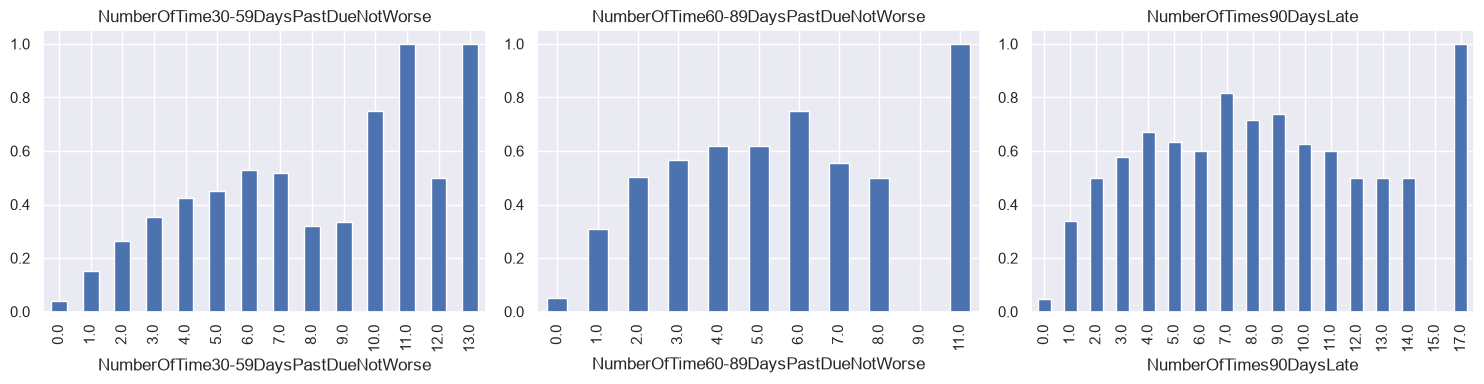

In [130]:
fig, axes = plt.subplots(1, len(atrasos.columns), figsize=(15, 4))

for ax, col in zip(axes, atrasos.columns):
    (
        train_df[[col, 'SeriousDlqin2yrs']]
        .groupby(col)
        .agg(taxa=('SeriousDlqin2yrs', 'mean'), n=('SeriousDlqin2yrs', 'count'))
        [['taxa']]
        .plot(kind='bar', ax=ax, legend=False, title=col)
    )

plt.tight_layout()
plt.show()

### Análise sobre Número de Dependentes

Analisando a distribuição dos dados. Apesar dos valores extremos, distribuição está dentro do esperado para a base

In [17]:
train_df['NumberOfDependents'].value_counts().sort_index()

NumberOfDependents
0.0     86902
1.0     26316
2.0     19522
3.0      9483
4.0      2862
5.0       746
6.0       158
7.0        51
8.0        24
9.0         5
10.0        5
13.0        1
20.0        1
Name: count, dtype: int64

Analisando agora os valores nulos. O NumberOfDependents não preenchido tem maior tendência para inadimplência. Provável que a coluna sinalizando tenha correlação forte com target

In [19]:
pd.crosstab(train_df.NumberOfDependents.isna(), train_df.SeriousDlqin2yrs,
            normalize='index')

SeriousDlqin2yrs,0,1
NumberOfDependents,,
False,0.932590,0.067410
True,0.954383,0.045617


Todos os registros com NumberOfDependents nulos tem MonthlyIncome nulo
também. O contrário acaba não acontecendo (86% dos registros com MI vazios
tem NumberOfDependents preenchidos)

In [20]:
pd.crosstab(train_df.NumberOfDependents.isna(),
            train_df.MonthlyIncome.isna())

MonthlyIncome,False,True
NumberOfDependents,,
False,120269,25807
True,0,3924


In [59]:
train_df['Missing-NumberOfDependents'] = train_df.NumberOfDependents.isna()

### Análise sobre Renda Mensal

Como esperado, distribuição da feature tem cauda longa. Para melhor visualização dos dados crio também feature log_MonthlyIncome, avaliar se vale manter dependendo do modelo que for escolhido

<Axes: >

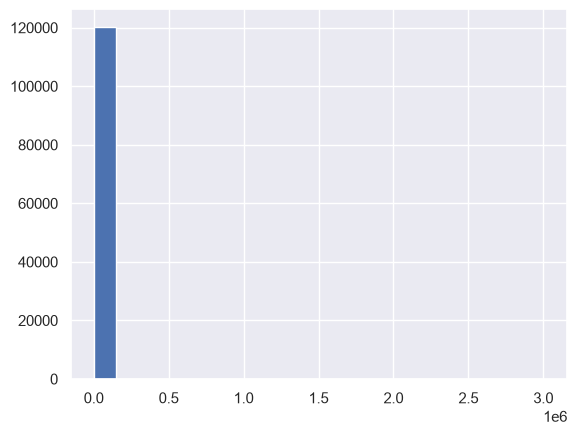

In [ ]:
renda = train_df.MonthlyIncome

renda.hist(bins=20);

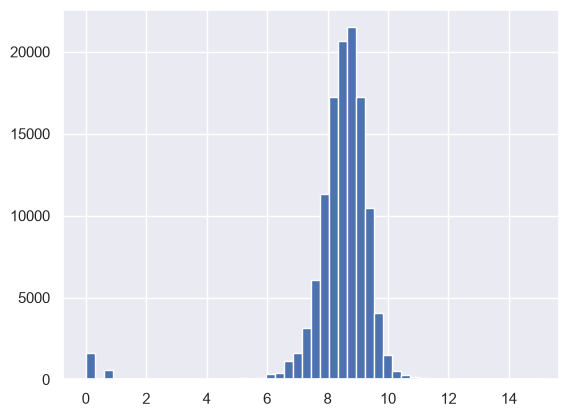

In [26]:
np.log1p(renda).hist(bins=50); # Distribuição log Renda tem cara normal com outliers para rendas baixa/sem renda

O MonthlyIncome não preenchido tem maior tendência para inadimplência. Coluna sinalizando vai ter alta correlação com o target

In [27]:
pd.crosstab(train_df.MonthlyIncome.isna(), train_df.SeriousDlqin2yrs,
            normalize='index')

SeriousDlqin2yrs,0,1
MonthlyIncome,,
False,0.930514,0.069486
True,0.943863,0.056137


In [58]:
train_df['Missing-MonthlyIncome'] = train_df.MonthlyIncome.isna()

### Análise sobre número de empréstimos imobiliários

Distribuição com cauda longa, concentrada clientes que nunca pediram/pediram 1 ou 2 empréstimos imobiliários

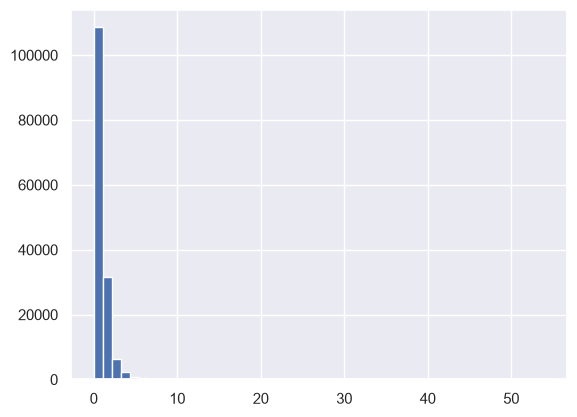

In [36]:
train_df.NumberRealEstateLoansOrLines.hist(bins=50);

### Análise sobre número de linhas de crédito abertas

De forma similar à feature # empréstimos imobiliários, aqui número de linhas de crédito abertas também possui cauda longa, com uma distribuição próxima normal com leve deformação à direita

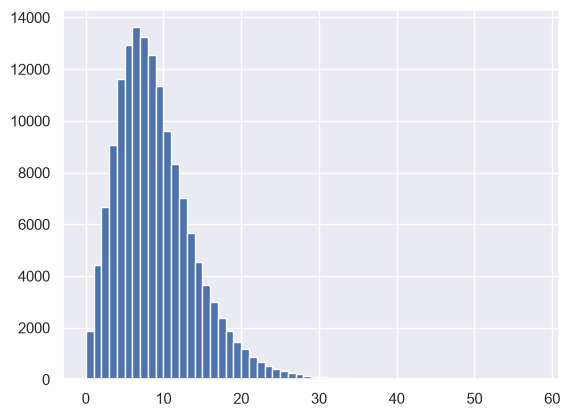

In [ ]:
train_df['NumberOfOpenCreditLinesAndLoans'].hist(bins=58);

### Análise sobre taxa de débito

In [46]:
taxas_debito = train_df['DebtRatio']

In [47]:
taxas_debito.describe()

count    150000.000000
mean        353.005076
std        2037.818523
min           0.000000
25%           0.175074
50%           0.366508
75%           0.868254
max      329664.000000
Name: DebtRatio, dtype: float64

Valores extremos estão puxando a média longe da mediana (longe até mesmo do terceiro quartil).<br>
Abaixo dá para perceber o enorme salto nos percentis 80 e 85

In [48]:
taxas_debito.quantile([0.5, .8, .85, 0.9, 0.99, 1])

0.50         0.366508
0.80         4.000000
0.85       269.150000
0.90      1267.000000
0.99      4979.040000
1.00    329664.000000
Name: DebtRatio, dtype: float64

Tentando entender melhor a distribuição desses valores altos na base, levanto a quantidade de vários theresholds diferentes.<br>
Parece ter uma queda significativa apenas após taxa de débito de 200x, o que já é absurdo

In [52]:
for limite in [4, 5, 10, 20, 50, 100, 200, 500, 1000, 10000]:
    print(f'> {limite}: {len(train_df.query('DebtRatio > @limite'))}')

> 4: 29891
> 5: 29646
> 10: 28877
> 20: 27862
> 50: 25934
> 100: 24380
> 200: 23088
> 500: 20602
> 1000: 16892
> 10000: 180


Vou tentar levantar associação com outras váriaveis.<br>
Observe que valores taxa de débito acima de 10 tem alta correlação com missing MonthlyIncome

In [ ]:
(
    train_df
    .assign(DEBITO_ALTO=lambda df: df.DebtRatio > 10)
    .corr()['DEBITO_ALTO'].sort_values(ascending=False)
)

DEBITO_ALTO                             1.000000
Missing-MonthlyIncome                   0.892727
DebtRatio                               0.354355
Missing-NumberOfDependents              0.253886
age                                     0.099068
NumberOfTimes90DaysLate                -0.003760
NumberOfTime60-89DaysPastDueNotWorse   -0.009915
SeriousDlqin2yrs                       -0.021742
NumberRealEstateLoansOrLines           -0.024960
NumberOfTime30-59DaysPastDueNotWorse   -0.034136
RevolvingUtilizationOfUnsecuredLines   -0.060257
MonthlyIncome                          -0.060806
NumberOfOpenCreditLinesAndLoans        -0.072362
NumberOfDependents                     -0.156588
Name: DEBITO_ALTO, dtype: float64

Hipótese aqui que quando MonthlyIncome é nulo, DebtRatio possa estar alterado, talvez porque a coluna DebtRatio foi sobrescrita com o MonthlyIncome (?). Vou seguir derrubando esses valores, mas vale avaliar impacto no modelo

In [88]:
pd.crosstab(train_df.DebtRatio > limite, train_df.MonthlyIncome.isna())

MonthlyIncome,False,True
DebtRatio,,
False,119269,13839
True,1000,15892


#### Tratamento

In [91]:
train_df.loc[train_df.MonthlyIncome.isna(), 'DebtRatio'] = np.nan

## Feature Engineering

In [83]:
def limpar_sujeiras(df):
       df = df.copy()
       df.loc[df['age'] == 0, 'age'] = np.nan
       df.loc[df['RevolvingUtilizationOfUnsecuredLines'] > 5, 
                 'RevolvingUtilizationOfUnsecuredLines'] = np.nan

       cols_atraso = [
              "NumberOfTime30-59DaysPastDueNotWorse",
              'NumberOfTime60-89DaysPastDueNotWorse',
              'NumberOfTimes90DaysLate'
       ]
       mask_atraso = df[cols_atraso].isin([96, 98])
       df[mask_atraso] = np.nan

       df.loc[df.MonthlyIncome.isna(), 'DebtRatio'] = np.nan
    
       return df

In [84]:
train_df = limpar_sujeiras(train_df)

In [85]:
def indicador_faltante(df, *cols):
    for col in cols:
        df[col+'_na'] = df[col].isna()
    return df

In [92]:
# Transformação 1 - impute
cols_faltantes = ['MonthlyIncome', 'NumberOfDependents', 'DebtRatio', 'age',
                  'RevolvingUtilizationOfUnsecuredLines', "NumberOfTime30-59DaysPastDueNotWorse",
                  'NumberOfTime60-89DaysPastDueNotWorse', 'NumberOfTimes90DaysLate']
imputer = SimpleImputer(strategy='median', add_indicator=True)
resultado = pd.DataFrame(imputer.fit_transform(train_df[cols_faltantes]),
                         columns=imputer.get_feature_names_out(),
                         index=train_df.index)
train_df = train_df.drop(cols_faltantes, axis=1).join(resultado)

In [93]:
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 1 to 150000
Data columns (total 21 columns):
 #   Column                                                 Non-Null Count   Dtype  
---  ------                                                 --------------   -----  
 0   SeriousDlqin2yrs                                       150000 non-null  int64  
 1   NumberOfOpenCreditLinesAndLoans                        150000 non-null  int64  
 2   NumberRealEstateLoansOrLines                           150000 non-null  int64  
 3   Missing-MonthlyIncome                                  150000 non-null  bool   
 4   Missing-NumberOfDependents                             150000 non-null  bool   
 5   MonthlyIncome                                          150000 non-null  float64
 6   NumberOfDependents                                     150000 non-null  float64
 7   DebtRatio                                              150000 non-null  float64
 8   age                                          

---

### 
Status até aqui: dados extraídos e sujeiras tratadas (age, RevolvingUtilization, atrasos, DebtRatio). Imputação aplicada com indicadores separados por origem do nulo. Próximo passo: correlação entre features e com o target, antes de decidir engenharia adicional.

In [94]:
testes = (
    train_df.copy()
    .assign(_soma_atrasos = lambda df: # A correlação dessa coluna sempre fica menor que a correlação de df['NumberOfTime30-59DaysPastDueNotWorse'], aumentando conforme coeficiente que acompanha essa feature aumenta com relação aos demais, e diminuindo no caso de outras combinações
            3*df['NumberOfTime30-59DaysPastDueNotWorse']+
            2*df['NumberOfTimes90DaysLate']+
            df['NumberOfTime60-89DaysPastDueNotWorse'])
    .assign(_dependentes_por_idade = lambda df: # Pensei que poderia ser significativo pois baixa idade e alto número de dependentes poderia indicar endividamento futuro, mas correlação ficou aquém da correlação de idade sozinha, não parece ser atributo interessante.
            df['NumberOfDependents']/df['age'])
    .assign(_debito_a_renda = lambda df: # Aqui considerei que proporção de débito indicaria tendência maior ao endividamento caso a renda fosse mais alta, visto que a dívida seria maior e portanto mais difícil de contornar
            df['DebtRatio']*df['MonthlyIncome'])
    .assign(_rotativo_para_outros_custos = lambda df: # Aqui pensei em considerar proporção para quantidade de linhas de rotativo sobre quantidade de crédito imobiliário, pois o primeiro indicaria tendência ao endividamento e, caso o segundo fosse pequeno/nulo, estaria ocorrendo endividamento sem fundos. Mas a correlação parece baixa
            df['RevolvingUtilizationOfUnsecuredLines']/(df['NumberRealEstateLoansOrLines']+1))
    .assign(_rotativo_por_linhas_credito = lambda df: # Considerei aqui a proporção do uso do rotativo ao uso de linhas de crédito, indicando tendência ao uso do rotativo para empréstimos
            df['RevolvingUtilizationOfUnsecuredLines']/df['NumberOfOpenCreditLinesAndLoans'])
    .assign(_renda_por_idade = lambda df:
            df['MonthlyIncome']/df['age'])
)

Abaixo, a matrix de correlação de pearson entre as features com a coluna target.<br>
Estão sendo apresentadas em ordem absoluta, diferenciando sinais.

---

As colunas missingindicator_NumberOfTime30-59DaysPastDueNotWorse, missingindicator_NumberOfTime60-89DaysPastDueNotWorse, missingindicator_NumberOfTimes90DaysLate são redundantes.

---

As colunas missingindicator_MonthlyIncome, missingindicator_DebtRatio são redundantes.

In [107]:
corr_mat = testes.corr()
resultado = (
    corr_mat[['SeriousDlqin2yrs']]
    .assign(sinal=lambda df: np.where(df['SeriousDlqin2yrs']>0,'+','-'))
    .assign(abs_corr=lambda df: np.abs(df.SeriousDlqin2yrs))
    .sort_values('abs_corr', ascending=False)
    .drop('SeriousDlqin2yrs', axis=1)
)
resultado

,sinal,abs_corr
SeriousDlqin2yrs,+,1.000000
_soma_atrasos,+,0.364028
NumberOfTimes90DaysLate,+,0.311713
RevolvingUtilizationOfUnsecuredLines,+,0.283979
NumberOfTime30-59DaysPastDueNotWorse,+,0.271411
NumberOfTime60-89DaysPastDueNotWorse,+,0.265594
_rotativo_para_outros_custos,+,0.261708
_rotativo_por_linhas_credito,+,0.176244
age,-,0.115397
missingindicator_NumberOfTimes90DaysLate,+,0.081401


In [ ]:
testes.drop(columns={'missingindicator_NumberOfTime60-89DaysPastDueNotWorse',
                     'missingindicator_NumberOfTime30-59DaysPastDueNotWorse',
                     'missingindicator_DebtRatio'}, inplace=True)

Fiz também análise com correlação de spearman para levantar possíveis relações não-lineares, mas nenhuma feature parece ter maior correlação

In [110]:
corr_mat = testes.corr(method='spearman')
resultado_ = resultado.reset_index().merge(
    corr_mat[['SeriousDlqin2yrs']]
    .assign(sinal_spearman=lambda df: np.where(df['SeriousDlqin2yrs']>0,'+','-'))
    .assign(abs_corr_spearman=lambda df: np.abs(df.SeriousDlqin2yrs))
    .sort_values('abs_corr_spearman', ascending=False)
    .drop('SeriousDlqin2yrs', axis=1)
    .reset_index()).set_index('index')
resultado_

,sinal,abs_corr,sinal_spearman,abs_corr_spearman
index,,,,
SeriousDlqin2yrs,+,1.000000,+,1.000000
_soma_atrasos,+,0.364028,+,0.326038
NumberOfTimes90DaysLate,+,0.311713,+,0.332203
RevolvingUtilizationOfUnsecuredLines,+,0.283979,+,0.240712
NumberOfTime30-59DaysPastDueNotWorse,+,0.271411,+,0.248156
NumberOfTime60-89DaysPastDueNotWorse,+,0.265594,+,0.265617
_rotativo_para_outros_custos,+,0.261708,+,0.224772
_rotativo_por_linhas_credito,+,0.176244,+,0.208189
age,-,0.115397,-,0.117038


In [155]:
# Maioria assimétrica
train_df[features_name].skew().sort_values(ascending=False)

MonthlyIncome                           127.121696
DebtRatio                                81.328092
NumberOfTimes90DaysLate                   9.343003
NumberOfTime60-89DaysPastDueNotWorse      7.555737
NumberOfTime30-59DaysPastDueNotWorse      4.251272
NumberRealEstateLoansOrLines              3.482484
NumberOfDependents                        1.626059
RevolvingUtilizationOfUnsecuredLines      1.225662
NumberOfOpenCreditLinesAndLoans           1.215314
age                                       0.189244
dtype: float64